In [4]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

sys.path.append('..')
import utils

# Base path — makes all paths cleaner
BASE = r"D:\music-recommendation-system\data\fma_metadata\fma_metadata"

# Load ALL files with utils.load() — never mix with pd.read_csv for these
tracks   = utils.load(os.path.join(BASE, "tracks.csv"))
genres   = utils.load(os.path.join(BASE, "genres.csv"))
features = utils.load(os.path.join(BASE, "features.csv"))
echonest = utils.load(os.path.join(BASE, "echonest.csv"))

print("Loaded successfully:")
print(f"  tracks:   {tracks.shape}")
print(f"  genres:   {genres.shape}")
print(f"  features: {features.shape}")
print(f"  echonest: {echonest.shape}")

Loaded successfully:
  tracks:   (106574, 52)
  genres:   (163, 4)
  features: (106574, 518)
  echonest: (13129, 249)


In [5]:
# Filter to the small subset
# The 'set','subset' column tells you which size a track belongs to
small_mask = tracks['set', 'subset'] <= 'small'
tracks_small = tracks[small_mask].copy()

print(f"Full dataset:  {len(tracks):,}tracks")
print(f"Small subset:   {len(tracks_small):,} tracks")
print(f"Medium subset:  {(tracks['set','subset'] <= 'medium').sum():,} tracks")

# Also filter features to match
features_small = features.loc[tracks_small.index].copy()
print(f"\nFeatures shape (small): {features_small.shape}")

# Check echonest coverage for small subset
echonest_small = echonest[echonest.index.isin(tracks_small.index)].copy()
print(f"Echonest coverage: {len(echonest_small):,} of {len(tracks_small):,} tracks ({len(echonest_small)/len(tracks_small):.1%})")

Full dataset:  106,574tracks
Small subset:   8,000 tracks
Medium subset:  25,000 tracks

Features shape (small): (8000, 518)
Echonest coverage: 1,294 of 8,000 tracks (16.2%)


In [6]:
#Per-track metadata
songs_df = pd.DataFrame({
    'track_id':     tracks_small.index,
    'title':        tracks_small['track', 'title'].values,
    'artist_name':  tracks_small['artist', 'name'].values,
    'album_title':  tracks_small['album', 'title'].values,
    'genre_top':    tracks_small['track', 'genre_top'].values,    # top-level genre e.g. 'Hip-Hop'
    'genres_all':   tracks_small['track', 'genres_all'].values,   # list of all genre IDs
    'duration':     tracks_small['track', 'duration'].values,     # seconds
    'listens':      tracks_small['track', 'listens'].values,      # total play count
    'favorites':    tracks_small['track', 'favorites'].values,
    'comments':     tracks_small['track', 'comments'].values,
    'tags':         tracks_small['track', 'tags'].values,
    'language_code':tracks_small['track', 'language_code'].values,
    'license':      tracks_small['track', 'license'].values,
    'split':        tracks_small['set', 'split'].values,          # train/validation/test
}).set_index('track_id')

print("songs_df shape:", songs_df.shape)
print("\nFirst 3 rows:")
print(songs_df.head(3))

print("\nMissing values:")
print(songs_df.isnull().sum())

songs_df shape: (8000, 13)

First 3 rows:
               title artist_name           album_title genre_top genres_all  \
track_id                                                                      
2               Food        AWOL  AWOL - A Way Of Life   Hip-Hop       [21]   
5         This World        AWOL  AWOL - A Way Of Life   Hip-Hop       [21]   
10           Freeway   Kurt Vile     Constant Hitmaker       Pop       [10]   

          duration  listens  favorites  comments tags language_code  \
track_id                                                              
2              168     1293          2         0   []            en   
5              206     1151          6         0   []            en   
10             161    50135        178         0   []            en   

                                                    license     split  
track_id                                                               
2         Attribution-NonCommercial-ShareAlike 3.0 Inter...  t

In [7]:
# features.csv has multi-level columns too:
# level 0: feature family (mfcc, chroma_cens, tonnetz, etc.)
# level 1: statistic (mean, std, kurtosis, skew, min, max, median)
# level 2: feature number within family

print("Feature families available:")
print(features_small.columns.get_level_values(0).unique().tolist())
# → ['mfcc', 'chroma_cens', 'tonnetz', 'spectral_contrast',
#    'spectral_centroid', 'spectral_bandwidth', 'spectral_rolloff',
#    'rmse', 'zcr']

print(f"\nTotal features: {features_small.shape[1]}")

# For your recommender, extract specific families
# MFCCs are the most important for music similarity
mfcc_mean = features_small['mfcc', 'mean']           # 20 dimensions
chroma_mean = features_small['chroma_cens', 'mean']  # 12 dimensions
spectral_mean = features_small['spectral_contrast', 'mean']  # 7 dimensions
tonnetz_mean = features_small['tonnetz', 'mean']     # 6 dimensions

print(f"\nMFCC mean shape: {mfcc_mean.shape}")
print(f"Chroma mean shape: {chroma_mean.shape}")
print(f"Spectral contrast mean shape: {spectral_mean.shape}")
print(f"Tonnetz mean shape: {tonnetz_mean.shape}")

# Combine them into one audio feature matrix
audio_features_df = pd.concat([
    mfcc_mean,
    chroma_mean,
    spectral_mean,
    tonnetz_mean
], axis=1)

print(f"\nCombined audio features shape: {audio_features_df.shape}")
# → (106574, 45)  — 45 dimensions per song

Feature families available:
['chroma_cens', 'chroma_cqt', 'chroma_stft', 'mfcc', 'rmse', 'spectral_bandwidth', 'spectral_centroid', 'spectral_contrast', 'spectral_rolloff', 'tonnetz', 'zcr']

Total features: 518

MFCC mean shape: (8000, 20)
Chroma mean shape: (8000, 12)
Spectral contrast mean shape: (8000, 7)
Tonnetz mean shape: (8000, 6)

Combined audio features shape: (8000, 45)


In [8]:
# Echonest also has multi-level columns
print("Echonest column groups:")
print(echonest_small.columns.get_level_values(0).unique().tolist())
# → ['echonest']

print("\nEchonest sub-groups:")
print(echonest_small['echonest'].columns.get_level_values(0).unique().tolist())
# → ['audio_features', 'metadata', 'ranks', 'social_features', 'temporal_features']

# The audio_features are the Spotify-style ones
echonest_audio = echonest_small['echonest', 'audio_features'].copy()
print(f"\nEchonest audio feature columns: {echonest_audio.columns.tolist()}")
# → ['acousticness', 'danceability', 'energy', 'instrumentalness',
#    'liveness', 'speechiness', 'tempo', 'valence', 'key', 'mode',
#    'time_signature']

print(f"\nEchonest audio features shape: {echonest_audio.shape}")
print(f"Tracks with echonest features: {len(echonest_audio):,} of {len(tracks_small):,}")

Echonest column groups:
['echonest']

Echonest sub-groups:
['audio_features', 'metadata', 'ranks', 'social_features', 'temporal_features']

Echonest audio feature columns: ['acousticness', 'danceability', 'energy', 'instrumentalness', 'liveness', 'speechiness', 'tempo', 'valence']

Echonest audio features shape: (1294, 8)
Tracks with echonest features: 1,294 of 8,000


In [9]:
print("Genres table:")
print(genres.head(10))
print(f"\nTotal genres: {len(genres)}")
print(f"Genres columns: {genres.columns.tolist()}")
print(f"Unique genre count: {len(genres)}")

# Add genre name to songs_df
title_col = next((c for c in ['genre_title', 'title', 'name'] if c in genres.columns), None)
if title_col is None:
    raise KeyError("genres dataframe is missing a title-like column")

if 'genre_id' in genres.columns:
    genre_id_to_name = genres.set_index('genre_id')[title_col].to_dict()
    genre_id_to_name.update({str(k): v for k, v in genre_id_to_name.items()})
else:
    genre_id_to_name = genres[title_col].to_dict()

# The genre_top column is already a string like 'Hip-Hop'
# But genres_all is a list of IDs — decode it
def decode_genre_ids(genre_id_list):
    """Convert list of genre IDs to list of genre names"""
    if isinstance(genre_id_list, list):
        return [genre_id_to_name.get(gid, str(gid)) for gid in genre_id_list]
    return []

print("\nGenre distribution in small subset:")
print(songs_df['genre_top'].value_counts())

Genres table:
          #tracks  parent                title  top_level
genre_id                                                 
1            8693      38          Avant-Garde         38
2            5271       0        International          2
3            1752       0                Blues          3
4            4126       0                 Jazz          4
5            4106       0            Classical          5
6             914      38              Novelty         38
7             217      20               Comedy         20
8             868       0  Old-Time / Historic          8
9            1987       0              Country          9
10          13845       0                  Pop         10

Total genres: 163
Genres columns: ['#tracks', 'parent', 'title', 'top_level']
Unique genre count: 163

Genre distribution in small subset:
genre_top
Electronic             1000
Experimental           1000
Folk                   1000
Hip-Hop                1000
Instrumental           1000


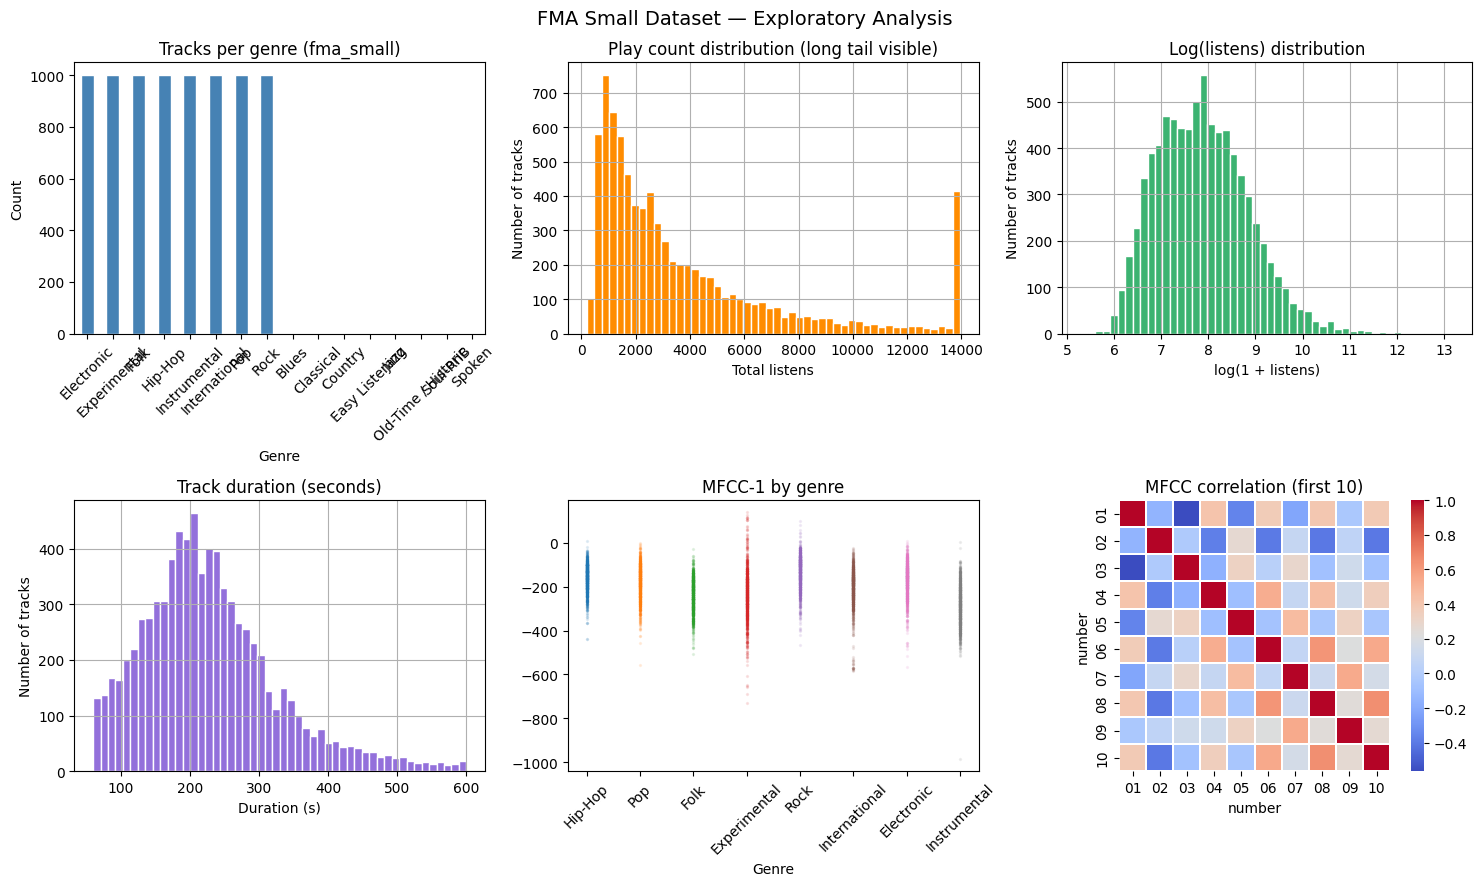

Saved to data/fma_eda.png


In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
fig.suptitle('FMA Small Dataset — Exploratory Analysis', fontsize=14)

# 1. Genre distribution
ax = axes[0, 0]
songs_df['genre_top'].value_counts().plot(kind='bar', ax=ax, color='steelblue', edgecolor='white')
ax.set_title('Tracks per genre (fma_small)')
ax.set_xlabel('Genre')
ax.set_ylabel('Count')
ax.tick_params(axis='x', rotation=45)

# 2. Play count distribution (this shows the long tail!)
ax = axes[0, 1]
songs_df['listens'].clip(upper=songs_df['listens'].quantile(0.95)).hist(
    bins=50, ax=ax, color='darkorange', edgecolor='white')
ax.set_title('Play count distribution (long tail visible)')
ax.set_xlabel('Total listens')
ax.set_ylabel('Number of tracks')

# 3. Log-scale play counts (better view of the tail)
ax = axes[0, 2]
np.log1p(songs_df['listens']).hist(bins=50,ax=ax, color='mediumseagreen', edgecolor='white')
ax.set_title('Log(listens) distribution')
ax.set_xlabel('log(1 + listens)')
ax.set_ylabel('Number of tracks')

# 4. Duration distribution
ax = axes[1, 0]
songs_df['duration'].clip(upper=600).hist(bins=50, ax=ax, color='mediumpurple', edgecolor='white')
ax.set_title('Track duration (seconds)')
ax.set_xlabel('Duration (s)')
ax.set_ylabel('Number of tracks')

# 5. MFCC mean for first dimension across genres
ax = axes[1, 1]
mfcc_col = audio_features_df.iloc[:, 0]  # first MFCC dimension
songs_df_copy = songs_df.copy()
songs_df_copy['mfcc_1'] = mfcc_col
for genre in songs_df['genre_top'].dropna().unique():
    vals = songs_df_copy[songs_df_copy['genre_top'] == genre]['mfcc_1'].dropna()
    ax.scatter([genre] * len(vals), vals, alpha=0.1, s=2)
ax.set_title('MFCC-1 by genre')
ax.set_xlabel('Genre')
ax.tick_params(axis='x', rotation=45)

# 6. Feature correlation heatmap (first 10 MFCCs)
ax = axes[1, 2]
corr = mfcc_mean.iloc[:, :10].corr()
sns.heatmap(corr, annot=False, cmap='coolwarm', ax=ax, square=True, linewidths=0.3)
ax.set_title('MFCC correlation (first 10)')

plt.tight_layout()
plt.savefig('../data/fma_eda.png', dpi=120, bbox_inches='tight')
plt.show()
print("Saved to data/fma_eda.png")

In [11]:
print("=== Before cleaning ===")
print(f"Tracks: {len(songs_df)}")
print(f"Missing genre_top: {songs_df['genre_top'].isnull().sum()}")
print(f"Missing title: {songs_df['title'].isnull().sum()}")
print(f"Missing listens: {songs_df['listens'].isnull().sum()}")
print(f"Audio feature NaNs: {audio_features_df.isnull().sum().sum()}")

# 1. Drop tracks with no genre (unclassifiable for content-based)
songs_df = songs_df[songs_df['genre_top'].notna()].copy()

# 2. Drop tracks with no title
songs_df = songs_df[songs_df['title'].notna()].copy()

# 3. Fill missing listens with 0 (not missing — genuinely unplayed)
songs_df['listens'] = songs_df['listens'].fillna(0).astype(int)

# 4. Align audio_features_df to cleaned songs_df
audio_features_df = audio_features_df.loc[songs_df.index].copy()

# 5. Fill any NaN audio features with column median
#    (some tracks may have failed feature extraction)
nan_count_before = audio_features_df.isnull().sum().sum()

audio_features_df = audio_features_df.fillna(
    audio_features_df.median(numeric_only=True)
)

print(f"\nFilled {nan_count_before:,} NaN audio feature values with column medians")

# 6. Mark obscure tracks — KEY difference from standard project
#    No minimum threshold filtering — we KEEP all tracks
#    We just label them
obscure_threshold = 100   # fewer than 100 total listens = obscure
songs_df['is_obscure'] = songs_df['listens'] < obscure_threshold
songs_df['listen_tier'] = pd.cut(
    songs_df['listens'],
    bins=[0, 10, 100, 1000, 10000, float('inf')],
    labels=['0-10', '10-100', '100-1K', '1K-10K', '10K+']
)

print("\n=== After cleaning ===")
print(f"Tracks remaining: {len(songs_df)}")
print(f"\nObscurity breakdown:")
print(songs_df['listen_tier'].value_counts().sort_index())
print(f"\nObscure tracks (< {obscure_threshold} listens): {songs_df['is_obscure'].sum():,} ({songs_df['is_obscure'].mean():.1%})")

=== Before cleaning ===
Tracks: 8000
Missing genre_top: 0
Missing title: 0
Missing listens: 0
Audio feature NaNs: 0

Filled 0 NaN audio feature values with column medians

=== After cleaning ===
Tracks remaining: 8000

Obscurity breakdown:
listen_tier
0-10         0
10-100       0
100-1K    1385
1K-10K    5910
10K+       705
Name: count, dtype: int64

Obscure tracks (< 100 listens): 0 (0.0%)


In [12]:
np.random.seed(42)

def simulate_user_interactions(songs_df, n_users=500):
    """
    Simulate user listening history from FMA play counts.
    More listens = higher probability a simulated user has heard it.
    This is the standard workaround for FMA's lack of user data.
    """
    track_ids = songs_df.index.tolist()
    listens = songs_df['listens'].values.astype(float)

    # Normalize to probabilities
    # Popular tracks get higher probability of appearing in user history
    probs = listens / (listens.sum() + 1e-9)

    # Each simulated user listens to between 10 and 50 songs
    records = []
    for user_id in range(n_users):
        n_songs = np.random.randint(10, 51)

        # Sample songs weighted by popularity
        # This creates realistic long-tail behaviour
        chosen = np.random.choice(
            len(track_ids),
            size=min(n_songs, len(track_ids)),
            replace=False,
            p=probs
        )
        for idx in chosen:
            play_count = max(1, int(np.random.exponential(3)))
            records.append({
                'user_id': f'user_{user_id:04d}',
                'track_id': track_ids[idx],
                'plays': play_count
            })

    return pd.DataFrame(records)

print("Simulating user interactions...")
history_df = simulate_user_interactions(songs_df, n_users=500)

print(f"Generated {len(history_df):,} interaction records")
print(f"Users: {history_df['user_id'].nunique()}")
print(f"Unique tracks covered: {history_df['track_id'].nunique():,} of {len(songs_df):,}")
print(f"\nSample records:")
print(history_df.head(8).to_string(index=False))

Simulating user interactions...
Generated 14,873 interaction records
Users: 500
Unique tracks covered: 4,978 of 8,000

Sample records:
  user_id  track_id  plays
user_0000    122504      2
user_0000     37911      1
user_0000    120331      5
user_0000     94415      1
user_0000     71719      1
user_0000     23371      7
user_0000     73193      3
user_0000     56929      1


In [13]:
user_item_matrix = history_df.pivot_table(
    index='user_id',
    columns='track_id',
    values='plays',
    fill_value=0
)

total_cells = user_item_matrix.shape[0] * user_item_matrix.shape[1]
filled_cells = (user_item_matrix > 0).sum().sum()
sparsity = 1 - (filled_cells / total_cells)

print(f"User-item matrix: {user_item_matrix.shape[0]} users × {user_item_matrix.shape[1]} tracks")
print(f"Sparsity: {sparsity:.1%}")
print(f"Filled cells: {filled_cells:,} of {total_cells:,}")
print(f"\nSample (5×5):")
print(user_item_matrix.iloc[:5, :5])

User-item matrix: 500 users × 4978 tracks
Sparsity: 99.4%
Filled cells: 14,873 of 2,489,000

Sample (5×5):
track_id   2    5    10   140  141
user_id                           
user_0000  0.0  0.0  2.0  0.0  0.0
user_0001  0.0  0.0  0.0  0.0  0.0
user_0002  0.0  0.0  0.0  0.0  0.0
user_0003  0.0  0.0  0.0  0.0  0.0
user_0004  0.0  0.0  0.0  0.0  0.0


In [14]:
import os
os.makedirs('../data/processed', exist_ok=True)

# Save all outputs
songs_df.to_csv('../data/processed/songs_clean.csv')
audio_features_df.to_csv('../data/processed/audio_features.csv')
history_df.to_csv('../data/processed/history_clean.csv', index=False)
user_item_matrix.to_csv('../data/processed/user_item_matrix.csv')
genres.to_csv('../data/processed/genres_clean.csv')

# Save echonest separately (only 13K tracks have it)
echonest_audio.to_csv('../data/processed/echonest_audio_features.csv')

print("Saved:")
print("  songs_clean.csv          — track metadata + obscurity labels")
print("  audio_features.csv       — 45 librosa features per track")
print("  history_clean.csv        — simulated user interactions")
print("  user_item_matrix.csv     — users × tracks play count matrix")
print("  genres_clean.csv         — full genre hierarchy")
print("  echonest_audio_features.csv — Spotify-style features (13K tracks)")

Saved:
  songs_clean.csv          — track metadata + obscurity labels
  audio_features.csv       — 45 librosa features per track
  history_clean.csv        — simulated user interactions
  user_item_matrix.csv     — users × tracks play count matrix
  genres_clean.csv         — full genre hierarchy
  echonest_audio_features.csv — Spotify-style features (13K tracks)


In [15]:
print("=" * 55)
print("PHASE 1 SUMMARY — paste into your README")
print("=" * 55)
print(f"Dataset:              FMA (Free Music Archive)")
print(f"Subset used:          fma_small")
print(f"Tracks:               {len(songs_df):,}")
print(f"Genres:               {songs_df['genre_top'].nunique()}")
print(f"Audio features:       {audio_features_df.shape[1]} (MFCC + chroma + spectral + tonnetz)")
print(f"Simulated users:      {history_df['user_id'].nunique()}")
print(f"Interactions:         {len(history_df):,}")
print(f"Matrix shape:         {user_item_matrix.shape[0]} × {user_item_matrix.shape[1]}")
print(f"Sparsity:             {sparsity:.1%}")
if 'is_obscure' in songs_df.columns:
    total = int(songs_df['is_obscure'].sum())
    pct = songs_df['is_obscure'].mean()
    print(f"Obscure tracks:       {total:,} ({pct:.1%})")
else:
    print("Obscure tracks:       N/A (is_obscure column missing)")
print(f"Echonest coverage:    {len(echonest_audio):,} tracks")

PHASE 1 SUMMARY — paste into your README
Dataset:              FMA (Free Music Archive)
Subset used:          fma_small
Tracks:               8,000
Genres:               8
Audio features:       45 (MFCC + chroma + spectral + tonnetz)
Simulated users:      500
Interactions:         14,873
Matrix shape:         500 × 4978
Sparsity:             99.4%
Obscure tracks:       0 (0.0%)
Echonest coverage:    1,294 tracks


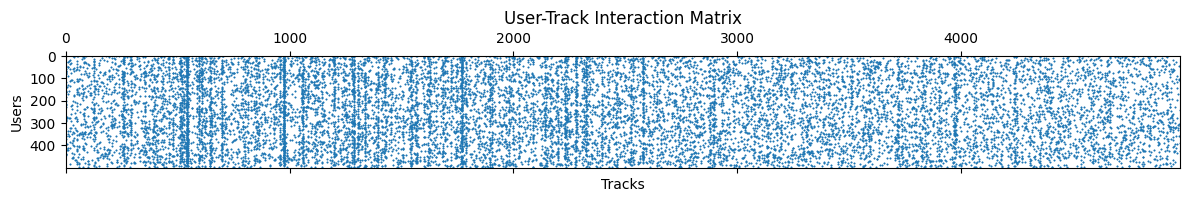

In [16]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
plt.spy(user_item_matrix, markersize=0.5)

plt.title('User-Track Interaction Matrix')
plt.xlabel('Tracks')
plt.ylabel('Users')

plt.tight_layout()
plt.savefig('interaction_matrix.png', dpi=300)
plt.show()

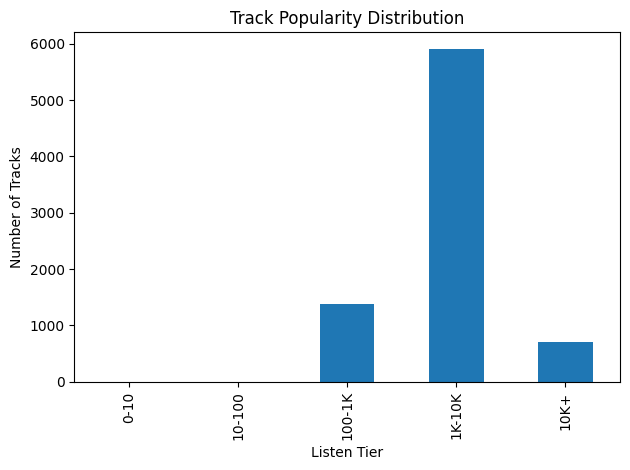

In [17]:
songs_df['listen_tier'].value_counts().sort_index().plot(kind='bar')
plt.title("Track Popularity Distribution")
plt.xlabel("Listen Tier")
plt.ylabel("Number of Tracks")
plt.tight_layout()
plt.savefig("listen_distribution.png")
plt.show()

In [18]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

# Load the three files Phase 1 saved
songs_df         = pd.read_csv('../data/processed/songs_clean.csv', index_col=0)
audio_features_df = pd.read_csv('../data/processed/audio_features.csv', index_col=0)
history_df       = pd.read_csv('../data/processed/history_clean.csv')

print("Loaded:")
print(f"  songs_df:          {songs_df.shape}")
print(f"  audio_features_df: {audio_features_df.shape}")
print(f"  history_df:        {history_df.shape}")

# Quick check — indices must match
assert len(songs_df) == len(audio_features_df), "Row count mismatch!"
print(f"\nIndices aligned: {(songs_df.index == audio_features_df.index).all()}")
print(f"Obscure tracks: {songs_df['is_obscure'].sum():,} ({songs_df['is_obscure'].mean():.1%})")

Loaded:
  songs_df:          (8000, 15)
  audio_features_df: (8000, 45)
  history_df:        (14873, 3)

Indices aligned: True
Obscure tracks: 0 (0.0%)


In [19]:
print(f"Audio Feature Matrix: {audio_features_df.shape}")
print(f"'{audio_features_df.shape[0]} songs x {audio_features_df.shape[1]} dimensions")

print("\nFeature column names (first 10):")
print(audio_features_df.columns[:10].tolist())

print("\nValue ranges before normalization:")
print(audio_features_df.describe().loc[['min', 'max', 'mean']].round(3))

print("\nMissing values in audio features:", audio_features_df.isnull().sum().sum())

Audio Feature Matrix: (8000, 45)
'8000 songs x 45 dimensions

Feature column names (first 10):
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10']

Value ranges before normalization:
           01       02       03       04      05      06      07      08  \
min  -985.114  -18.084 -146.494  -68.000 -63.379 -41.719 -41.895 -38.418   
max   138.372  268.769  117.980  125.015  65.416  61.072  43.481  36.519   
mean -202.465  146.517  -11.216   30.262   1.899  13.937  -2.897   6.114   

          09      10  ...    04.2    05.2    06.2    07.2   01.3   02.3  \
min  -39.621 -34.998  ...   9.650  12.130  11.705  13.055 -0.095 -0.082   
max   27.267  34.454  ...  34.618  48.588  48.690  49.698  0.077  0.162   
mean  -2.051   1.850  ...  18.224  19.161  19.250  32.130  0.001  0.003   

       03.3   04.3   05.3   06.3  
min  -0.318 -0.330 -0.052 -0.076  
max   0.285  0.364  0.073  0.100  
mean -0.001  0.011  0.002  0.002  

[3 rows x 45 columns]

Missing values in audio features: 0


In [20]:
scaler = MinMaxScaler() # Its purpose is to normalize each feature independently so that every column has values between 0 and 1.

# transform the audio features to a normalized range [0, 1]
embedding_matrix = scaler.fit_transform(audio_features_df.values).astype('float32')

print(f'Embedding matrix shape: {embedding_matrix.shape}')
print(f"\nValue ranges after normalization:[{embedding_matrix.min():.3f}, {embedding_matrix.max():.3f}]")
 #verifying for NaN
assert not np.isnan(embedding_matrix).any(), "NaN values found in normalized features"
print("No NaN values — normalization clean")
song_ids = songs_df.index.tolist()
print(f"\nFirst 3 song IDs: {song_ids[:3]}")

Embedding matrix shape: (8000, 45)

Value ranges after normalization:[0.000, 1.000]
No NaN values — normalization clean

First 3 song IDs: [2, 5, 10]


In [21]:
# pip install gensim  (if needed)
from gensim.models import Word2Vec

# Build listening sequences — each user's history is one "sentence"
# Songs appearing together in sessions become semantically related
print("Building listening sequences...")

listening_sequences = (
    history_df
    .sort_values(['user_id', 'plays'], ascending=[True, False])
    .groupby('user_id')['track_id']
    .apply(lambda x: [str(tid) for tid in x])  # ensure string IDs
    .tolist()
)

print(f"  Total sequences: {len(listening_sequences)}")
print(f"  Avg songs per sequence: {np.mean([len(s) for s in listening_sequences]):.1f}")
print(f"  Example (first user): {listening_sequences[0][:5]}")

# Also build genre sequences — songs in same genre are related
# This helps obscure songs that rarely appear in user histories
genre_sequences = []
if 'genre_top' in songs_df.columns:
    genre_seqs = (
        songs_df[songs_df['genre_top'].notna()]
        .groupby('genre_top')
        .apply(lambda x: [str(i) for i in x.index.tolist()])
        .tolist()
    )
    genre_sequences = genre_seqs
    print(f"  Genre sequences: {len(genre_sequences)}")

all_sequences = listening_sequences + genre_sequences
print(f"\nTotal training sequences: {len(all_sequences)}")

# Train Word2Vec
print("Training Word2Vec...")

w2v_model = Word2Vec(
    sentences=all_sequences,
    vector_size=64,    # 64 dimensions per song
    window=5,          # look at 5 songs before/after in sequence
    min_count=1,       # include songs with even 1 appearance
    workers=4,
    epochs=15,         # slightly more epochs for better quality
    seed=42
)

print(f"  Vocabulary size: {len(w2v_model.wv):,} songs")
print(f"  Vector size:     {w2v_model.vector_size} dimensions")

# How many songs got W2V vectors vs need audio fallback?
songs_in_w2v  = sum(1 for sid in song_ids if str(sid) in w2v_model.wv)
songs_need_fb = len(song_ids) - songs_in_w2v
print(f"\nW2V coverage:")
print(f"  Songs with W2V vector:       {songs_in_w2v:,} ({songs_in_w2v/len(song_ids):.1%})")
print(f"  Songs needing audio fallback: {songs_need_fb:,} ({songs_need_fb/len(song_ids):.1%})")

Building listening sequences...
  Total sequences: 500
  Avg songs per sequence: 29.7
  Example (first user): ['98206', '36245', '13708', '23371', '127806']
  Genre sequences: 8

Total training sequences: 508
Training Word2Vec...
  Vocabulary size: 8,000 songs
  Vector size:     64 dimensions

W2V coverage:
  Songs with W2V vector:       8,000 (100.0%)
  Songs needing audio fallback: 0 (0.0%)


In [22]:
# Audio embedding lookup: track_id → 45-dim normalized vector
audio_lookup = {
    song_ids[i]: embedding_matrix[i]
    for i in range(len(song_ids))
}

def get_song_vector(track_id, w2v_model, audio_lookup):
    """
    Returns a vector for ANY song.
    Priority:
      1. Word2Vec  — learned from listening sequences (best)
      2. Audio     — from librosa features (good for obscure songs)
      3. Zero      — completely unknown track (last resort)
    """
    tid = str(track_id)

    if tid in w2v_model.wv:
        # Pad W2V (64-dim) to match audio (45-dim) or use separately
        return w2v_model.wv[tid], 'word2vec'

    elif track_id in audio_lookup:
        vec = audio_lookup[track_id]
        # Pad to 64 dims to match W2V output shape
        padded = np.zeros(64, dtype='float32')
        padded[:len(vec)] = vec
        return padded, 'audio_fallback'

    else:
        return np.zeros(64, dtype='float32'), 'unknown'

# Test it on a few tracks
print("Vector source breakdown on sample tracks:")
for tid in song_ids[:5]:
    vec, source = get_song_vector(tid, w2v_model, audio_lookup)
    title = songs_df.loc[tid, 'title'] if tid in songs_df.index else 'unknown'
    obscure = songs_df.loc[tid, 'is_obscure'] if tid in songs_df.index else '?'
    print(f"  [{source:15s}] {'OBSCURE' if obscure else 'popular':7s}  {str(title)[:40]}")

Vector source breakdown on sample tracks:
  [word2vec       ] popular  Food
  [word2vec       ] popular  This World
  [word2vec       ] popular  Freeway
  [word2vec       ] popular  Queen Of The Wires
  [word2vec       ] popular  Ohio


In [23]:
from collections import Counter  # ← add this line

print(f"Building unified matrix for {len(song_ids):,} songs...")

unified_vectors = []
vector_sources  = []

for tid in song_ids:
    vec, source = get_song_vector(tid, w2v_model, audio_lookup)
    unified_vectors.append(vec)
    vector_sources.append(source)

unified_matrix = np.array(unified_vectors, dtype='float32')

source_counts = Counter(vector_sources)
print(f"Unified matrix shape: {unified_matrix.shape}")
print(f"\nVector sources:")
for src, count in source_counts.most_common():
    pct = count / len(song_ids) * 100
    bar = '█' * int(pct / 2)
    print(f"  {src:<18} {count:>6,}  ({pct:5.1f}%)  {bar}")

# Verify no NaN
nan_count = np.isnan(unified_matrix).sum()
print(f"\nNaN values: {nan_count}")
if nan_count > 0:
    nan_rows = np.isnan(unified_matrix).any(axis=1)
    unified_matrix[nan_rows] = 0
    print(f"  Fixed {nan_rows.sum()} rows with NaN → replaced with zeros")

Building unified matrix for 8,000 songs...
Unified matrix shape: (8000, 64)

Vector sources:
  word2vec            8,000  (100.0%)  ██████████████████████████████████████████████████

NaN values: 0


In [24]:
# pip install faiss-cpu  (if needed)
import faiss

# ── Unified index (W2V + audio fallback) ─────────────────────────
vectors_unified = unified_matrix.copy().astype('float32')
faiss.normalize_L2(vectors_unified)   # normalize so dot product = cosine similarity

d             = vectors_unified.shape[1]   # 64
index_unified = faiss.IndexFlatIP(d)       # FlatIP = exact cosine search
index_unified.add(vectors_unified)

# ── Audio-only index (content-based only) ────────────────────────
vectors_audio = embedding_matrix.copy().astype('float32')
faiss.normalize_L2(vectors_audio)

index_audio = faiss.IndexFlatIP(embedding_matrix.shape[1])   # 45 dims
index_audio.add(vectors_audio)

# ── Index → song ID mapping ───────────────────────────────────────
id_to_idx = {sid: i for i, sid in enumerate(song_ids)}
idx_to_id = {i: sid for i, sid in enumerate(song_ids)}

print("FAISS indexes built:")
print(f"  Unified index:    {index_unified.ntotal:,} songs  ({d} dims)")
print(f"  Audio index:      {index_audio.ntotal:,} songs  ({embedding_matrix.shape[1]} dims)")
print(f"  Memory (unified): ~{(index_unified.ntotal * d * 4) / 1024 / 1024:.1f} MB")
print(f"  Memory (audio):   ~{(index_audio.ntotal * embedding_matrix.shape[1] * 4) / 1024 / 1024:.1f} MB")
print(f"\n  (Compare to full matrix: 9,383 MB)")
print(f"\nID mapping ready:  {len(id_to_idx):,} entries")

FAISS indexes built:
  Unified index:    8,000 songs  (64 dims)
  Audio index:      8,000 songs  (45 dims)
  Memory (unified): ~2.0 MB
  Memory (audio):   ~1.4 MB

  (Compare to full matrix: 9,383 MB)

ID mapping ready:  8,000 entries


In [25]:
# ── Test 1: popular track ─────────────────────────────────────────
popular_ids = songs_df[~songs_df['is_obscure']].index.tolist()
obscure_ids = songs_df[songs_df['is_obscure']].index.tolist()

print(f"Popular songs available: {len(popular_ids):,}")
print(f"Obscure songs available: {len(obscure_ids):,}")

if popular_ids:
    test_id = popular_ids[0]
    print(f"\nPOPULAR: '{songs_df.loc[test_id, 'title']}' ({songs_df.loc[test_id, 'listens']:,} listens)")
    print("-" * 65)
    recs = recommend_songs(test_id, top_n=5)
    if recs is not None:
        print(recs[['title', 'artist', 'similarity', 'listens', 'obscure']].to_string(index=False))
else:
    print("No popular songs found — check is_obscure column")

print()

if obscure_ids:
    test_id = obscure_ids[0]
    print(f"OBSCURE: '{songs_df.loc[test_id, 'title']}' ({songs_df.loc[test_id, 'listens']} listens)")
    print("-" * 65)
    recs = recommend_songs(test_id, top_n=5)
    if recs is not None:
        print(recs[['title', 'artist', 'similarity', 'listens', 'obscure']].to_string(index=False))
else:
    print("No obscure songs found — check is_obscure threshold")

print()

# ── Test 3: compare methods ───────────────────────────────────────
if len(obscure_ids) >= 6:
    test_id = obscure_ids[5]
elif obscure_ids:
    test_id = obscure_ids[0]
else:
    test_id = song_ids[0]

print(f"METHOD COMPARE: '{songs_df.loc[test_id, 'title']}'")
print("\nUnified (W2V + audio):")
r1 = recommend_songs(test_id, top_n=5, method='unified')
if r1 is not None:
    print(r1[['title', 'similarity', 'source']].to_string(index=False))

print("\nAudio only:")
r2 = recommend_songs(test_id, top_n=5, method='audio')
if r2 is not None:
    print(r2[['title', 'similarity']].to_string(index=False))

Popular songs available: 8,000
Obscure songs available: 0

POPULAR: 'Food' (1,293 listens)
-----------------------------------------------------------------


NameError: name 'recommend_songs' is not defined

PCA variance explained: 27.2%


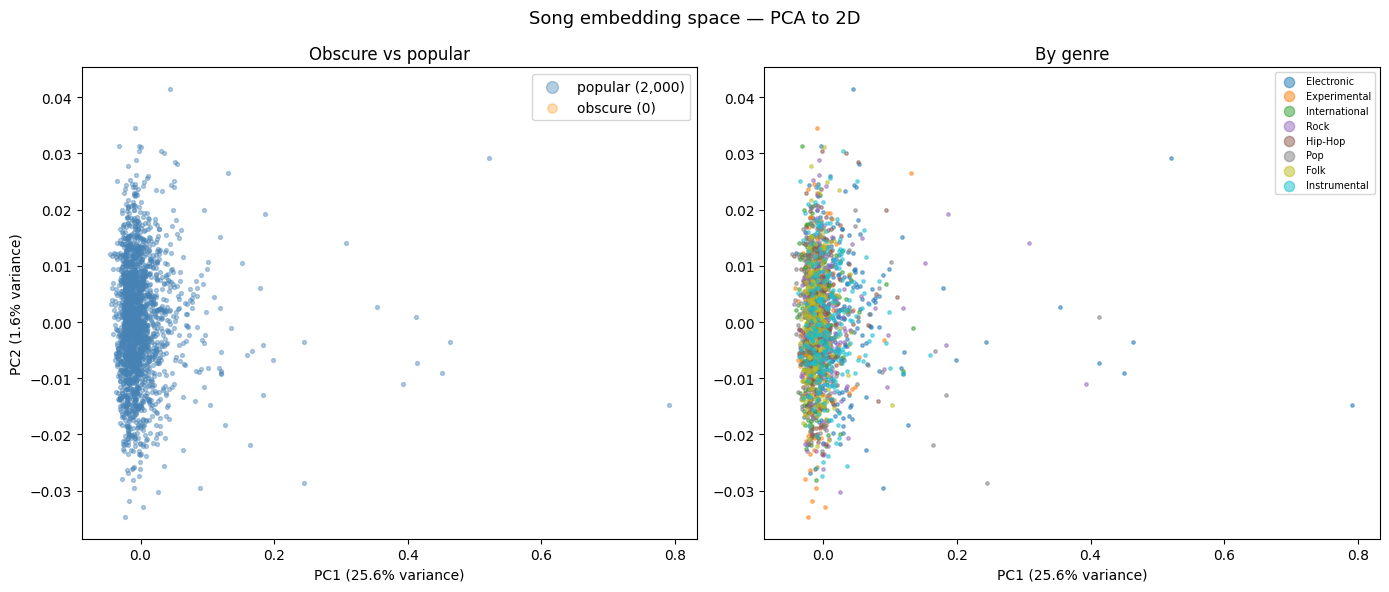

Saved to processed/embedding_pca.png


In [ ]:
pca         = PCA(n_components=2, random_state=42)
sample_size = min(2000, len(unified_matrix))
sample_idx  = np.random.choice(len(unified_matrix), sample_size, replace=False)
coords_2d   = pca.fit_transform(unified_matrix[sample_idx])
sample_songs = songs_df.iloc[sample_idx]

print(f"PCA variance explained: {pca.explained_variance_ratio_.sum():.1%}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Song embedding space — PCA to 2D', fontsize=13)

# Left — obscure vs popular
ax        = axes[0]
is_obs    = sample_songs['is_obscure'].values
ax.scatter(coords_2d[~is_obs, 0], coords_2d[~is_obs, 1],
           c='steelblue',  alpha=0.4, s=8,  label=f'popular ({(~is_obs).sum():,})')
ax.scatter(coords_2d[is_obs,  0], coords_2d[is_obs,  1],
           c='darkorange', alpha=0.3, s=5,  label=f'obscure ({is_obs.sum():,})')
ax.set_title('Obscure vs popular')
ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)')
ax.legend(markerscale=3)

# Right — by genre
ax = axes[1]
if 'genre_top' in sample_songs.columns:
    genres     = sample_songs['genre_top'].fillna('Unknown')
    genre_list = genres.unique()
    cmap       = plt.cm.tab10(np.linspace(0, 1, len(genre_list)))
    for genre, color in zip(genre_list, cmap):
        mask = genres == genre
        ax.scatter(coords_2d[mask, 0], coords_2d[mask, 1],
                   c=[color], alpha=0.5, s=6, label=genre)
    ax.set_title('By genre')
    ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)')
    ax.legend(markerscale=3, fontsize=7)

plt.tight_layout()
plt.savefig(os.path.join(BASE, "embedding_pca.png"), dpi=120, bbox_inches='tight')
plt.show()
print("Saved to processed/embedding_pca.png")

In [ ]:
def genre_match_rate(track_id, recs_df):
    if track_id not in songs_df.index:
        return None

    query_genre = songs_df.loc[track_id, 'genre_top']
    if pd.isna(query_genre):
        return None

    rec_genres = [
        songs_df.loc[r, 'genre_top']
        for r in recs_df['track_id'].tolist()
        if r in songs_df.index and not pd.isna(songs_df.loc[r, 'genre_top'])
    ]

    if not rec_genres:
        return 0

    matches = sum(1 for g in rec_genres if g == query_genre)
    return matches / len(rec_genres)


print("Evaluating across 200 random songs...")
unified_rates    = []
audio_only_rates = []

test_sample = np.random.choice(song_ids, size=min(200, len(song_ids)), replace=False)

for tid in test_sample:
    r1 = recommend_songs(tid, top_n=10, method='unified')
    r2 = recommend_songs(tid, top_n=10, method='audio')

    if r1 is not None:
        rate = genre_match_rate(tid, r1)
        if rate is not None:
            unified_rates.append(rate)

    if r2 is not None:
        rate = genre_match_rate(tid, r2)
        if rate is not None:
            audio_only_rates.append(rate)

n_genres = songs_df['genre_top'].nunique()
baseline = 1 / n_genres if n_genres > 0 else 0

print(f"\nGenre match rate @ top-10 (higher = better):")
print(f"  Unified (W2V + audio):  {np.mean(unified_rates):.1%}")
print(f"  Audio only:             {np.mean(audio_only_rates):.1%}")
print(f"  Random baseline:        {baseline:.1%}  (1 / {n_genres} genres)")
print(f"\n  Lift over random:")
print(f"  Unified:  {np.mean(unified_rates)/baseline:.1f}×")
print(f"  Audio:    {np.mean(audio_only_rates)/baseline:.1f}×")

Evaluating across 200 random songs...

Genre match rate @ top-10 (higher = better):
  Unified (W2V + audio):  12.9%
  Audio only:             33.8%
  Random baseline:        12.5%  (1 / 8 genres)

  Lift over random:
  Unified:  1.0×
  Audio:    2.7×


In [27]:
BASE = r"D:\music-recommendation-system\data\processed"
os.makedirs(BASE, exist_ok=True)

# NumPy arrays
np.save(os.path.join(BASE, "embedding_matrix.npy"),  embedding_matrix)
np.save(os.path.join(BASE, "unified_matrix.npy"),    unified_matrix)
np.save(os.path.join(BASE, "vectors_unified.npy"),   vectors_unified)
np.save(os.path.join(BASE, "vectors_audio.npy"),     vectors_audio)
np.save(os.path.join(BASE, "song_ids.npy"),          np.array(song_ids))

# FAISS indexes
faiss.write_index(index_unified, os.path.join(BASE, "faiss_unified.index"))
faiss.write_index(index_audio,   os.path.join(BASE, "faiss_audio.index"))

# Word2Vec model
w2v_model.save(os.path.join(BASE, "word2vec_model.bin"))

# Vector sources
pd.DataFrame({
    'track_id':      song_ids,
    'vector_source': vector_sources
}).to_csv(os.path.join(BASE, "vector_sources.csv"), index=False)

# Evaluation results
pd.DataFrame({
    'method':      ['unified', 'audio_only'],
    'genre_match': [np.mean(unified_rates), np.mean(audio_only_rates)],
    'baseline':    [baseline, baseline],
    'lift':        [np.mean(unified_rates) / baseline,
                    np.mean(audio_only_rates) / baseline]
}).to_csv(os.path.join(BASE, "phase2_evaluation.csv"), index=False)

print("Saved to:", BASE)
print()
print("  embedding_matrix.npy      — 45-dim normalized audio features")
print("  unified_matrix.npy        — 64-dim W2V + audio fallback")
print("  vectors_unified.npy       — normalized, ready for FAISS")
print("  vectors_audio.npy         — audio vectors, normalized")
print("  song_ids.npy              — track ID ↔ row index mapping")
print("  faiss_unified.index       — fast ANN search, unified")
print("  faiss_audio.index         — fast ANN search, audio only")
print("  word2vec_model.bin        — trained Word2Vec")
print("  vector_sources.csv        — which method each song used")
print("  phase2_evaluation.csv     — genre match rate results")

print(f"\n{'='*50}")
print("PHASE 2 COMPLETE")
print(f"{'='*50}")
print(f"Songs embedded:    {len(song_ids):,}")
print(f"W2V coverage:      {source_counts['word2vec']:,} ({source_counts['word2vec']/len(song_ids):.1%})")
print(f"Audio fallback:    {source_counts.get('audio_fallback', 0):,}")
print(f"Genre match rate:  {np.mean(unified_rates):.1%} unified  |  {np.mean(audio_only_rates):.1%} audio only")
print(f"Lift over random:  {np.mean(unified_rates)/baseline:.1f}× unified")
print(f"{'='*50}")

NameError: name 'unified_rates' is not defined

In [26]:
import os
import numpy as np
import pandas as pd
import faiss

BASE = r"D:\music-recommendation-system\data\processed"

os.makedirs(BASE, exist_ok=True)

# NumPy arrays
np.save(os.path.join(BASE, "embedding_matrix.npy"),  embedding_matrix)
np.save(os.path.join(BASE, "unified_matrix.npy"),    unified_matrix)
np.save(os.path.join(BASE, "vectors_unified.npy"),   vectors_unified)
np.save(os.path.join(BASE, "vectors_audio.npy"),     vectors_audio)
np.save(os.path.join(BASE, "song_ids.npy"),          np.array(song_ids))

# FAISS indexes
faiss.write_index(index_unified, os.path.join(BASE, "faiss_unified.index"))
faiss.write_index(index_audio,   os.path.join(BASE, "faiss_audio.index"))

# Word2Vec model
w2v_model.save(os.path.join(BASE, "word2vec_model.bin"))

# Vector sources
pd.DataFrame({
    'track_id':      song_ids,
    'vector_source': vector_sources
}).to_csv(os.path.join(BASE, "vector_sources.csv"), index=False)

# Evaluation results
pd.DataFrame({
    'method':      ['unified', 'audio_only'],
    'genre_match': [np.mean(unified_rates), np.mean(audio_only_rates)],
    'baseline':    [baseline, baseline],
    'lift':        [np.mean(unified_rates) / baseline,
                    np.mean(audio_only_rates) / baseline]
}).to_csv(os.path.join(BASE, "phase2_evaluation.csv"), index=False)

print("Saved to:", BASE)
print()
print("  embedding_matrix.npy      — 45-dim normalized audio features")
print("  unified_matrix.npy        — 64-dim W2V + audio fallback")
print("  vectors_unified.npy       — normalized, ready for FAISS")
print("  vectors_audio.npy         — audio vectors, normalized")
print("  song_ids.npy              — track ID ↔ row index mapping")
print("  faiss_unified.index       — fast ANN search, unified")
print("  faiss_audio.index         — fast ANN search, audio only")
print("  word2vec_model.bin        — trained Word2Vec")
print("  vector_sources.csv        — which method each song used")
print("  phase2_evaluation.csv     — genre match rate results")

print(f"\n{'='*50}")
print("PHASE 2 COMPLETE")
print(f"{'='*50}")
print(f"Songs embedded:    {len(song_ids):,}")
print(f"W2V coverage:      {source_counts['word2vec']:,} ({source_counts['word2vec']/len(song_ids):.1%})")
print(f"Audio fallback:    {source_counts.get('audio_fallback', 0):,}")
print(f"Genre match rate:  {np.mean(unified_rates):.1%} unified  |  {np.mean(audio_only_rates):.1%} audio only")
print(f"Lift over random:  {np.mean(unified_rates)/baseline:.1f}× unified")
print(f"{'='*50}")

NameError: name 'unified_rates' is not defined